# Lab 3: Building nanoGPT

Adapted from Andrej Karpathy's "Let's build GPT":
- https://www.youtube.com/watch?v=kCc8FmEb1nY and
- https://colab.research.google.com/drive/1JMLa53HDuA-i7ZBmqV7ZnA3c_fvtXnx-?usp=sharing


## Import Dependencies

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)


## Import Dataset

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-31 07:45:33--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt.4’

input.txt.4         100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-31 07:45:33 (30.5 MB/s) - ‘input.txt.4’ saved [1115394/1115394]



In [ ]:
# with open('input.txt', 'r', encoding='utf-8') as f:
#     text = f.read()


In [ ]:
from datasets import load_dataset

ds = load_dataset("roneneldan/TinyStories")

In [ ]:
stories = []
for row in ds["validation"]:
  t = row["text"].strip()
  if t:
    stories.append(t)

text = "\n\n".join(stories)

In [ ]:
print("length of dataset in characters: ", len(text))


length of dataset in characters:  19234296


In [ ]:
# let's look at the first 1000 characters
print(text[:1000])


Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."

After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They played together all day and became best friends.

Once upon a time, in a big forest, there lived a rhinoceros named Roxy. Roxy loved to climb. She climbed trees, rocks, and hills. One day, Roxy found an icy hill. She had never seen anything like it before. It was shiny and cold, and she wanted to climb it.

Roxy tried to climb the icy hill, but it was very slippery. She tried again and again, but she kept falling down. Roxy was sad. She wanted to climb the icy hill so much. Then, she saw a little bird named Billy. Billy saw that Roxy was sad and asked, "Why are you sad, Roxy?"

Roxy told Billy about the icy hill and how she couldn't climb it. Billy said, "I have an idea! Let's find some big

In [ ]:
# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)


In [ ]:
print(''.join(chars))
print(vocab_size)



 !"#$&'()*+,-./0123456789:;<?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz¦©­±´ÂÃâðœŠŸŽ˜“”‹€™
101


## Character-level Tokenizer

In [ ]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }

# encoder: take a string, output a list of integers
encode = lambda s: [stoi[c] for c in s]

# decoder: take a list of integers, output a string
decode = lambda l: ''.join([itos[i] for i in l])


In [ ]:
print(encode("Hello World!"))
print(decode(encode("Hello World!")))


[37, 60, 67, 67, 70, 1, 52, 70, 73, 67, 59, 2]
Hello World!


In [ ]:
# Tokenize our dataset
data = torch.tensor(encode(text), dtype=torch.long)


In [ ]:
print(data.shape, data.dtype)
print(data[:1000])


torch.Size([19234296]) torch.int64
tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75,  1, 74, 56, 78,  1, 75, 63, 60,
         1, 74, 63, 64, 69, 80,  1, 58, 56, 73,  1, 56, 69, 59,  1, 74, 56, 64,
        59, 12,  1,  3, 52, 70, 78, 12,  1, 40, 64, 75, 75, 80, 12,  1, 80, 70,
        76, 73,  1, 58, 56, 73,  1, 64, 74,  1, 74, 70,  1, 57, 73, 64, 62, 63,
        75,  1, 56, 69, 59,  1, 58, 67, 60, 56, 69,  2,  3,  1, 40, 64, 75, 75,
        80,  1, 74, 68, 64, 67, 60, 59,  1, 56, 69, 59,  1, 73, 60, 71, 67, 64,
        60, 59, 12,  1,  3, 49, 63, 56, 69, 66,  1, 80, 70, 76, 12,  1, 48, 71,
        70, 75, 14,  1, 38,  1, 71, 70, 67, 64, 74, 63,  1, 64, 75,  1, 60, 77,
        60, 73, 80,  1, 59, 56, 80, 14,  3,  0,  0, 30, 61, 75, 60, 73,  1, 71,
        67, 56, 80, 64, 69, 62,  1, 78, 64, 75, 63,  1, 75, 63, 60,  1, 58, 56,
        73, 12,  1, 40, 64, 75, 75, 80,  1, 56, 69, 59,  1, 48, 71, 70, 75,  1,
        61, 60, 67, 75,  1, 75, 63, 64, 73, 74, 75, 80, 14,  1, 49, 63, 60, 80,
     

## Train Validation Split

In [ ]:
n = int(0.9*len(data))
train_data = data[:n]
val_data = data[n:]


## Context Length

(Also called Block Size of Sequence Length)

In [ ]:
context_length = 8
train_data[:context_length+1]


tensor([48, 71, 70, 75, 14,  1, 48, 71, 70])

In [ ]:
x = train_data[:context_length]
y = train_data[1:context_length+1]
for t in range(context_length):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")


when input is tensor([48]) the target: 71
when input is tensor([48, 71]) the target: 70
when input is tensor([48, 71, 70]) the target: 75
when input is tensor([48, 71, 70, 75]) the target: 14
when input is tensor([48, 71, 70, 75, 14]) the target: 1
when input is tensor([48, 71, 70, 75, 14,  1]) the target: 48
when input is tensor([48, 71, 70, 75, 14,  1, 48]) the target: 71
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71]) the target: 70


## Create Batches

In [ ]:
batch_size = 16  # how many independent sequences will we process in parallel?
context_length = 32  # 32 instead of 8 for better training

def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - context_length, (batch_size,))
    x = torch.stack([data[i:i+context_length] for i in ix])  # 16 by 32 tensor (batch_size x context_length)
    y = torch.stack([data[i+1:i+context_length+1] for i in ix])
    x, y = x.to(device), y.to(device)  # cuda or cpu
    return x, y



In [ ]:
# Example
for t in range(context_length):
    context = train_data[:context_length][:t+1]
    target = train_data[1:context_length+1][t]
    print(f"when input is {context} the target: {target}")


when input is tensor([48]) the target: 71
when input is tensor([48, 71]) the target: 70
when input is tensor([48, 71, 70]) the target: 75
when input is tensor([48, 71, 70, 75]) the target: 14
when input is tensor([48, 71, 70, 75, 14]) the target: 1
when input is tensor([48, 71, 70, 75, 14,  1]) the target: 48
when input is tensor([48, 71, 70, 75, 14,  1, 48]) the target: 71
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71]) the target: 70
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70]) the target: 75
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75]) the target: 1
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75,  1]) the target: 74
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75,  1, 74]) the target: 56
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75,  1, 74, 56]) the target: 78
when input is tensor([48, 71, 70, 75, 14,  1, 48, 71, 70, 75,  1, 74, 56, 78]) the target: 1
when input is tensor([48, 71, 70, 75, 14,  1, 48, 7

In [ ]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class SelfAttentionHead(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(context_length, context_length)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2,-1) * C**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        out = wei @ v
        return out

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([SelfAttentionHead(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class TransformerLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(context_length, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))  # abs
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -context_length:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


In [ ]:
max_iters = 1000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0


In [ ]:
model = TransformerLanguageModel()
m = model.to(device)
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


0.214373 M parameters


In [ ]:
for iter in range(max_iters):
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# Expected loss at start: -ln(1/65) = 4.1743872699


step 0: train loss 4.7967, val loss 4.7955
step 100: train loss 2.4996, val loss 2.4815
step 200: train loss 2.3163, val loss 2.3056
step 300: train loss 2.2100, val loss 2.2036
step 400: train loss 2.1265, val loss 2.1182
step 500: train loss 2.0495, val loss 2.0466
step 600: train loss 1.9912, val loss 1.9851
step 700: train loss 1.9206, val loss 1.9346
step 800: train loss 1.8673, val loss 1.8802
step 900: train loss 1.8079, val loss 1.8126
step 999: train loss 1.7639, val loss 1.7714


In [ ]:
print(decode(model.generate(torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=500)[0].tolist()))




Her, AThey fouft wllay bighteark the do it men'telaing yor, Jouth ond ve youdder. "I clay uckinged. Sat and they bllaigig a wosed were sreepe. Hut was fry grees waske, he novogs him saie cante. The days you and to foar the to onem. Ben aâ€ht want to bot fahingso. They and wet her happy her and crouch heand. Than doowily ould logaikeng where.

Lily shily was havooked tad.

O boie tom the feckethers. They ero day, wann, thas hem wallaylle nam a bet harry toy. Some obo and they hat corming zire up


## Save checkpoint

model weights + hyperparams + vocabulary

In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'vocab_size': vocab_size,
    'stoi': stoi,
    'itos': itos,
    'n_embd': n_embd,
    'n_head': n_head,
    'n_layer': n_layer,
    'context_length': context_length,
    'dropout': dropout,
}, 'nanogpt_checkpoint.pt')
print("Model saved to nanogpt_checkpoint.pt")


Model saved to nanogpt_checkpoint.pt


## Load and generate

Load checkpoint and restore weights into the existing model

In [ ]:
checkpoint = torch.load('nanogpt_checkpoint.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print("Model loaded successfully.")

# Generate
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=2000)[0].tolist()))


Model loaded successfully.

The voway?"

Onto was offly them pere.âenely.


Wennuttily witarkith to it. Flas so the help heaved so abryinbed hilb dow didnot oncidene thoubediented. Theyey she wanted happy a Theey saidd to day dargaing it to klay cand otheld and Don the hat of agax ant hime they was time do ffs. The wecked and on king frum thend erstaitem.

Ande, Mick They too asked is him. 
The veirneng dond, saway cas shed the rack pimberts, she chisiside. "Nom we to that he or hank oughack nored wasiden herd bht Timm on and the his for tree. Fr? She saing fam drughenvey but incits hom whinxhins angref." Whe apwenclys tould tooketheth somengred and. Ony't kis herr mom geaved. "The 5im." Lis dijncand wen exto jumed Tich smet, Thappy ould theard sfilde. She affor findng wette the he froven lovere. Tommy qughind.

"Moance daSut's sto lot vaved ittsiliting. Att when sthe reend a coands.

They the he day and kendrianded,ing So howising end it rier toold k homy dich vee. It le herimmy wante

# (Untested Vibe Lab) Mixture of Experts (MoE)

So far every token passes through the same feed-forward network (FFN) in each block. In a **Mixture of Experts** model, the FFN is replaced by several FFNs ("experts") plus a small **router**. For each token, the router picks one (or a few) experts, and only those are computed.

- **Total parameters** grow with the number of experts (more capacity).
- **Active parameters per token** stay roughly the same as the dense model (same compute per token).

Attention, embeddings, the language-model head, and the training loop stay the same. Only the FFN in each block changes.

We use the Switch Transformer setup: `top_k = 1`, each expert the same size as our `FeedFoward`. That way the MoE model does the same amount of computation per token as the dense model from Part 1, which makes the comparison fair.


## Keep the Dense Model

We keep the trained dense model from Part 1 for the comparison at the end. If you restarted the kernel, run the cells of Part 1 up to the model definition, then the "Load and generate" cell, before continuing.


In [ ]:
dense_model = model


## MoE Hyperparameters

Evaluation was most of the compute in Part 1 (`eval_iters = 200` batches for train and val every 100 steps), so we evaluate less often here. Keep `max_iters` the same as for the dense model for a fair comparison; reduce it if training is too slow on your laptop.


In [ ]:
n_experts = 4       # number of expert FFNs per block
top_k = 1           # experts per token (1 = Switch Transformer)
aux_coef = 0.01     # weight of the load-balancing loss
eval_interval = 500
eval_iters = 100


## Router and Experts

The router is a single linear layer that turns each token's vector into one score per expert. A softmax turns the scores into probabilities, and each token is sent to its `top_k` experts. The expert output is multiplied by the router probability, so the router receives a gradient and learns which expert to choose.

Note: for `top_k = 1` we do **not** renormalize the selected probability. Renormalizing would always give a weight of exactly 1.0, so no gradient would reach the router and it would never learn.

**Load-balancing loss.** On its own, the router tends to collapse: it sends most tokens to one or two experts, which then get more training and become even more attractive. The auxiliary loss from the Switch Transformer paper prevents this:

$$\mathcal{L}_{aux} = N \sum_{i=1}^{N} f_i \cdot P_i$$

where $N$ is the number of experts, $f_i$ the fraction of tokens sent to expert $i$, and $P_i$ the mean router probability for expert $i$. It equals 1.0 when the load is perfectly balanced and grows up to $N$ when all tokens go to a single expert.


In [ ]:
class MoE(nn.Module):
    def __init__(self, n_embd, n_experts, top_k):
        super().__init__()
        self.top_k = top_k
        self.router = nn.Linear(n_embd, n_experts, bias=False)
        self.experts = nn.ModuleList([FeedFoward(n_embd) for _ in range(n_experts)])  # same FFN as Part 1
        self.aux_loss = torch.tensor(0.0)
        self.last_choice = None  # top-1 expert per token, for visualization

    def forward(self, x):
        B, T, C = x.shape
        x = x.view(B*T, C)                             # route every token independently
        probs = F.softmax(self.router(x), dim=-1)      # (B*T, n_experts)
        top_p, top_i = probs.topk(self.top_k, dim=-1)  # (B*T, top_k)
        if self.top_k > 1:
            top_p = top_p / top_p.sum(dim=-1, keepdim=True)
        out = torch.zeros_like(x)
        for e, expert in enumerate(self.experts):
            tok, slot = (top_i == e).nonzero(as_tuple=True)  # tokens routed to expert e
            if tok.numel() > 0:
                out = out.index_add(0, tok, top_p[tok, slot, None] * expert(x[tok]))
        # load-balancing loss
        E = probs.shape[-1]
        frac = F.one_hot(top_i, E).float().sum(dim=1).mean(dim=0) / self.top_k  # f_i
        self.aux_loss = E * (frac * probs.mean(dim=0)).sum()
        self.last_choice = top_i[:, 0].view(B, T).detach()
        return out.view(B, T, C)


## MoE Block and Model

The MoE block is the dense `Block` with the FFN replaced, and the MoE model is the dense model with MoE blocks. It also collects the load-balancing loss of all blocks. `generate` is inherited unchanged.


In [ ]:
class MoEBlock(Block):
    def __init__(self, n_embd, n_head):
        super().__init__(n_embd, n_head)
        self.ffwd = MoE(n_embd, n_experts, top_k)  # the only change

class MoELanguageModel(TransformerLanguageModel):
    def __init__(self):
        super().__init__()
        self.blocks = nn.Sequential(*[MoEBlock(n_embd, n_head=n_head) for _ in range(n_layer)])

    def forward(self, idx, targets=None):
        logits, loss = super().forward(idx, targets)  # loss is still the plain cross-entropy
        self.aux_loss = sum(block.ffwd.aux_loss for block in self.blocks)
        return logits, loss


## Total vs. Active Parameters


In [ ]:
torch.manual_seed(1337)
model = MoELanguageModel()
m = model.to(device)

total_params = sum(p.numel() for p in m.parameters())
expert_params = sum(p.numel() for p in m.blocks[0].ffwd.experts[0].parameters())
active_params = total_params - n_layer * (n_experts - top_k) * expert_params
print(total_params/1e6, 'M parameters (total)')
print(active_params/1e6, 'M parameters (active per token)')
print(sum(p.numel() for p in dense_model.parameters())/1e6, 'M parameters (dense model)')

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


0.612453 M parameters (total)
0.215397 M parameters (active per token)
0.214373 M parameters (dense model)


## Train the MoE Model

Same training loop as before, with one change: the load-balancing loss is added to the cross-entropy before `backward()`. We also print how the tokens are distributed over the experts in the first block.


In [ ]:
@torch.no_grad()
def expert_utilization(mdl, X=None):
    # fraction of tokens routed to each expert (rows = layers, columns = experts)
    if X is not None:
        mdl.eval()
        mdl(X)
        mdl.train()
    usage = [torch.bincount(b.ffwd.last_choice.flatten(), minlength=n_experts).float()
             / b.ffwd.last_choice.numel() for b in mdl.blocks]
    return torch.stack(usage)


In [ ]:
for iter in range(max_iters):
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}, aux loss {model.aux_loss.item():.4f}")
        print("    expert usage (block 0):", [round(u, 2) for u in expert_utilization(model)[0].tolist()])
    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    (loss + aux_coef * model.aux_loss).backward()  # cross-entropy + load-balancing loss
    optimizer.step()


step 0: train loss 4.7854, val loss 4.7888, aux loss 4.2853
    expert usage (block 0): [0.25, 0.21, 0.27, 0.27]
step 500: train loss 2.0152, val loss 1.9968, aux loss 4.0429
    expert usage (block 0): [0.26, 0.29, 0.18, 0.28]
step 999: train loss 1.7079, val loss 1.7099, aux loss 4.0167
    expert usage (block 0): [0.26, 0.27, 0.23, 0.23]


In [ ]:
print(decode(model.generate(torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=500)[0].tolist()))





One them huLe, pll a went the got pon. But the kind her. But Jird frieciy, detharged pra upon. Jokn fox opery and had it smily.

"Yen said, Lily and said, Lily was her a no sgo him saie cun the up to martee, ther foar the to onem. Bok and to dearturing faht nea. The say, were every the sturthere Timmy and. Timmy and had all lugaike kinn gard hught him goth to you mothom. One it tom theree was lestrings. Hory a, wann, that he day andled nearave the rusticy. She would her end eat con it ozire up


## Expert Utilization

Fraction of tokens each expert receives in each block, on a validation batch. With the load-balancing loss, the values should be close to `1 / n_experts`.


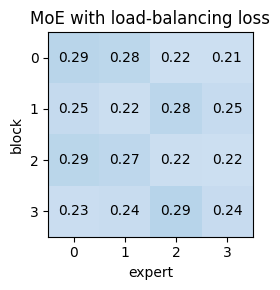

In [ ]:
import matplotlib.pyplot as plt

def plot_utilization(usage, ax, title):
    usage = usage.cpu()
    ax.imshow(usage, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n_experts))
    ax.set_yticks(range(n_layer))
    ax.set_xlabel('expert')
    ax.set_ylabel('block')
    ax.set_title(title)
    for l in range(n_layer):
        for e in range(n_experts):
            ax.text(e, l, f'{usage[l, e]:.2f}', ha='center', va='center')

X_val, _ = get_batch('val')
fig, ax = plt.subplots(figsize=(5, 3))
plot_utilization(expert_utilization(model, X_val), ax, 'MoE with load-balancing loss')
plt.tight_layout()
plt.show()


## What Do the Experts Specialize In?

For each expert, the characters it receives most often. At character level the specialization is rough, but you may see experts that prefer spaces and punctuation, capital letters, or vowels. Try different blocks with `layer`.


In [ ]:
layer = 0
counts = torch.zeros(n_experts, vocab_size)
model.eval()
with torch.no_grad():
    for _ in range(50):
        X, _ = get_batch('val')
        model(X)
        choice = model.blocks[layer].ffwd.last_choice
        for e in range(n_experts):
            counts[e] += torch.bincount(X[choice == e].cpu(), minlength=vocab_size).float()
model.train()

frequent = counts.sum(dim=0) >= 20  # ignore rare characters
for e in range(n_experts):
    share = counts[e] / counts.sum(dim=0).clamp(min=1) * frequent  # share of each character that goes to expert e
    top = share.argsort(descending=True)[:10]
    print(f"expert {e} ({(counts[e].sum() / counts.sum()).item():.0%} of tokens):",
          ' '.join(repr(itos[i.item()]) for i in top))


expert 0 (26% of tokens): 'u' 'g' 'l' 'd' 'p' 'k' '.' 'm' '"' 'L'
expert 1 (28% of tokens): 'S' ' ' 'j' 'H' 'b' 'T' 'f' 'w' '!' 'c'
expert 2 (24% of tokens): 'B' 'o' ',' 'O' 's' 'v' 'I' 'x' 'r' 'M'
expert 3 (22% of tokens): "'" 'a' 'i' 'Y' 'y' 'r' '.' 'n' '\n' '"'


## Routing Visualization

A validation passage, each character colored by the expert chosen in block `layer`. The text is fed in chunks of `context_length` characters.


In [ ]:
from IPython.display import HTML, display
from html import escape

colors = ['#fbb4ae', '#b3cde3', '#ccebc5', '#decbe4', '#fed9a6', '#ffffcc', '#e5d8bd', '#fddaec']

def show_routing(mdl, sample, layer=0):
    idx = torch.tensor(encode(sample), dtype=torch.long, device=device)
    n_chunks = len(idx) // context_length
    idx = idx[:n_chunks * context_length].view(n_chunks, context_length)
    mdl.eval()
    with torch.no_grad():
        mdl(idx)
    mdl.train()
    choice = mdl.blocks[layer].ffwd.last_choice.flatten().tolist()
    spans = []
    for ch, e in zip(decode(idx.flatten().tolist()), choice):
        ch = '↵<br>' if ch == '\n' else escape(ch).replace(' ', '&nbsp;')
        spans.append(f'<span style="background:{colors[e % len(colors)]}; color:black">{ch}</span>')
    legend = ' '.join(f'<span style="background:{colors[e % len(colors)]}; color:black">&nbsp;expert {e}&nbsp;</span>'
                      for e in range(n_experts))
    display(HTML(f'<p>{legend}</p><p style="font-family:monospace">{"".join(spans)}</p>'))

show_routing(model, decode(val_data[:640].tolist()), layer=0)


## Experiment: Without the Load-Balancing Loss

Train a second MoE model for a shorter time with `aux_coef = 0` and compare the expert utilization. Without the auxiliary loss, the router often sends most tokens to a few experts (collapse), and the other experts are wasted parameters.


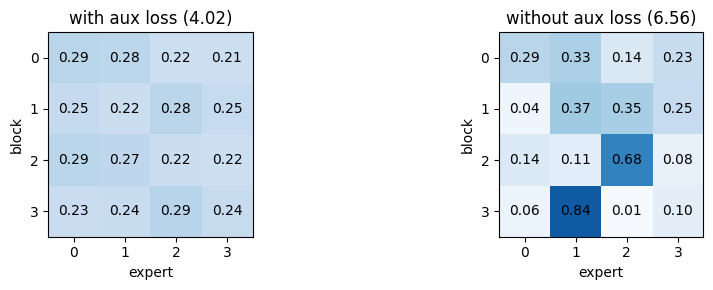

In [ ]:
torch.manual_seed(1337)
model_no_aux = MoELanguageModel().to(device)
optimizer_no_aux = torch.optim.AdamW(model_no_aux.parameters(), lr=learning_rate)

for iter in range(2000):
    xb, yb = get_batch('train')
    logits, loss = model_no_aux(xb, yb)
    optimizer_no_aux.zero_grad(set_to_none=True)
    loss.backward()  # cross-entropy only, no load-balancing loss
    optimizer_no_aux.step()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
plot_utilization(expert_utilization(model, X_val), axes[0], f'with aux loss ({model.aux_loss.item():.2f})')
plot_utilization(expert_utilization(model_no_aux, X_val), axes[1], f'without aux loss ({model_no_aux.aux_loss.item():.2f})')
plt.tight_layout()
plt.show()


## Comparison: Dense vs. MoE

Same data, same number of training steps, (almost) the same compute per token.


In [ ]:
import time

@torch.no_grad()
def val_loss(mdl, iters=eval_iters):
    mdl.eval()
    losses = torch.zeros(iters)
    for k in range(iters):
        X, Y = get_batch('val')
        _, loss = mdl(X, Y)
        losses[k] = loss.item()
    mdl.train()
    return losses.mean().item()

def ms_per_step(mdl, steps=20):
    xb, yb = get_batch('train')
    for i in range(steps + 3):
        if i == 3:  # first 3 steps are warm-up
            if device == 'cuda': torch.cuda.synchronize()
            t0 = time.perf_counter()
        logits, loss = mdl(xb, yb)
        loss.backward()
        mdl.zero_grad(set_to_none=True)
    if device == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / steps * 1000

dense_params = sum(p.numel() for p in dense_model.parameters())
print(f"{'':8}{'total':>10}{'active':>10}{'val loss':>10}{'ms/step':>10}")
print(f"{'dense':8}{dense_params/1e6:>9.3f}M{dense_params/1e6:>9.3f}M{val_loss(dense_model):>10.4f}{ms_per_step(dense_model):>10.1f}")
print(f"{'MoE':8}{total_params/1e6:>9.3f}M{active_params/1e6:>9.3f}M{val_loss(model):>10.4f}{ms_per_step(model):>10.1f}")


             total    active  val loss   ms/step
dense       0.214M    0.214M    1.7808      30.2
MoE         0.612M    0.215M    1.7072      38.1


In [ ]:
for name, mdl in [('dense', dense_model), ('MoE', model)]:
    torch.manual_seed(42)
    print(f'--- {name} ---')
    print(decode(mdl.generate(torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=300)[0].tolist()))


--- dense ---

Maxd the sulided. It herlown her her to she was darts.

One way girry fe cabalt to ther and tosoilsir hourt, Mors, "" Jolly. I was was, someching dows. He at rabfuch her a wast she ounded shifdele. Lily hirg a ving his toings. It wavey her woille she park in. It nasming sa lack bick and ast herndy l
--- MoE ---



Lily were all want and said his to to she was darturl got's ron a yon back fund. Same scant soiled and tow Moriver hon her nother yolded tay bear as. Her the boug yout a was and to nook's with a to bellirg a ving his to ple gird.

Ald The on and helpothon.. Then's daying the thing leards. Then tur


## Discussion

- The MoE model has about 3× the parameters but the same compute per token. Did that lower the validation loss? Compare the gap between train and val loss for both models. What does that suggest about MoE on a dataset of only ~1M characters?
- The MoE model is slower per step even though it does the same number of FLOPs. Why? (Hint: look at the loop over the experts in `MoE.forward`. What do production systems do instead?)
- What changes if you set `top_k = 2`? Count the active parameters again.
- A model like Mixtral 8x7B has ~47B total but ~13B active parameters. What does this mean for the GPU memory needed vs. the compute per token?


## Save MoE Checkpoint

model weights + hyperparams (incl. MoE settings) + vocabulary


In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'vocab_size': vocab_size,
    'stoi': stoi,
    'itos': itos,
    'n_embd': n_embd,
    'n_head': n_head,
    'n_layer': n_layer,
    'context_length': context_length,
    'dropout': dropout,
    'n_experts': n_experts,
    'top_k': top_k,
    'aux_coef': aux_coef,
}, 'nanogpt_moe_checkpoint.pt')
print("Model saved to nanogpt_moe_checkpoint.pt")


Model saved to nanogpt_moe_checkpoint.pt
